# Chest X-Ray Disease Classification - Part 1: Lung Segmentation (U-Net)

COVID-19 Radiography Database, 4 classes (COVID, Normal, Viral Pneumonia, Lung Opacity).

**This notebook covers:** dataset loading and class balancing, train/validation/test split, U-Net training for lung segmentation, Dice evaluation, and generation of segmented lung images.

**Still in progress (not included yet):** ConvNeXt + RepViT classification, Grad-CAM and final evaluation.

In [1]:
import os

DATASET_PATH = "/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset path:", DATASET_PATH)

if os.path.exists(DATASET_PATH):
    print("\nItems:")
    for item in sorted(os.listdir(DATASET_PATH)):
        print(item)

Dataset exists: True
Dataset path: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset

Items:
COVID
COVID.metadata.xlsx
Lung_Opacity
Lung_Opacity.metadata.xlsx
Normal
Normal.metadata.xlsx
README.md.txt
Viral Pneumonia
Viral Pneumonia.metadata.xlsx


In [2]:
import os

CLASS_MAP = {
    "COVID": "COVID",
    "Normal": "Normal",
    "Viral Pneumonia": "Viral Pneumonia",
    "Lung Opacity": "Lung_Opacity"
}

for class_name, folder_name in CLASS_MAP.items():
    class_path = os.path.join(DATASET_PATH, folder_name)
    image_path = os.path.join(class_path, "images")
    mask_path = os.path.join(class_path, "masks")

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    masks = [
        f for f in os.listdir(mask_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"\n{class_name}")
    print("Folder:", class_path)
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Images folder exists:", os.path.isdir(image_path))
    print("Masks folder exists:", os.path.isdir(mask_path))


COVID
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID
Images: 3616
Masks: 3616
Images folder exists: True
Masks folder exists: True

Normal
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal
Images: 10192
Masks: 10192
Images folder exists: True
Masks folder exists: True

Viral Pneumonia
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia
Images: 1345
Masks: 1345
Images folder exists: True
Masks folder exists: True

Lung Opacity
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity
Images: 6012
Masks: 6012
Images folder exists: True
Masks folder exists: True


In [3]:
import os

for class_name, folder_name in CLASS_MAP.items():
    image_path = os.path.join(DATASET_PATH, folder_name, "images")
    mask_path = os.path.join(DATASET_PATH, folder_name, "masks")

    image_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    mask_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(mask_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    matched = image_files & mask_files
    missing_masks = image_files - mask_files
    missing_images = mask_files - image_files

    print(f"\n{class_name}")
    print("Images:", len(image_files))
    print("Masks:", len(mask_files))
    print("Matched:", len(matched))
    print("Missing masks:", len(missing_masks))
    print("Missing images:", len(missing_images))

    if missing_masks:
        print("Example missing masks:", list(missing_masks)[:5])

    if missing_images:
        print("Example missing images:", list(missing_images)[:5])


COVID
Images: 3616
Masks: 3616
Matched: 3616
Missing masks: 0
Missing images: 0

Normal
Images: 10192
Masks: 10192
Matched: 10192
Missing masks: 0
Missing images: 0

Viral Pneumonia
Images: 1345
Masks: 1345
Matched: 1345
Missing masks: 0
Missing images: 0

Lung Opacity
Images: 6012
Masks: 6012
Matched: 6012
Missing masks: 0
Missing images: 0


In [4]:
import os
import random
import pandas as pd

SEED = 42
SAMPLES_PER_CLASS = 1345

random.seed(SEED)

records = []

for label, (class_name, folder_name) in enumerate(CLASS_MAP.items()):
    image_path = os.path.join(DATASET_PATH, folder_name, "images")
    mask_path = os.path.join(DATASET_PATH, folder_name, "masks")

    image_files = sorted([
        f for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    selected_files = random.sample(image_files, SAMPLES_PER_CLASS)

    for filename in selected_files:
        records.append({
            "image_path": os.path.join(image_path, filename),
            "mask_path": os.path.join(mask_path, filename),
            "class_name": class_name,
            "label": label
        })

df = pd.DataFrame(records)

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

csv_path = "/kaggle/working/balanced_5380_dataset.csv"
df.to_csv(csv_path, index=False)

print("Total samples:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts().sort_index())

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\nCSV saved to:", csv_path)

print("\nFirst 5 records:")
print(df.head())

Total samples: 5380

Class distribution:
class_name
COVID              1345
Lung Opacity       1345
Normal             1345
Viral Pneumonia    1345
Name: count, dtype: int64

Label distribution:
label
0    1345
1    1345
2    1345
3    1345
Name: count, dtype: int64

CSV saved to: /kaggle/working/balanced_5380_dataset.csv

First 5 records:
                                          image_path  \
0  /kaggle/input/datasets/tawsifurrahman/covid19-...   
1  /kaggle/input/datasets/tawsifurrahman/covid19-...   
2  /kaggle/input/datasets/tawsifurrahman/covid19-...   
3  /kaggle/input/datasets/tawsifurrahman/covid19-...   
4  /kaggle/input/datasets/tawsifurrahman/covid19-...   

                                           mask_path    class_name  label  
0  /kaggle/input/datasets/tawsifurrahman/covid19-...         COVID      0  
1  /kaggle/input/datasets/tawsifurrahman/covid19-...  Lung Opacity      3  
2  /kaggle/input/datasets/tawsifurrahman/covid19-...         COVID      0  
3  /kaggle/input/

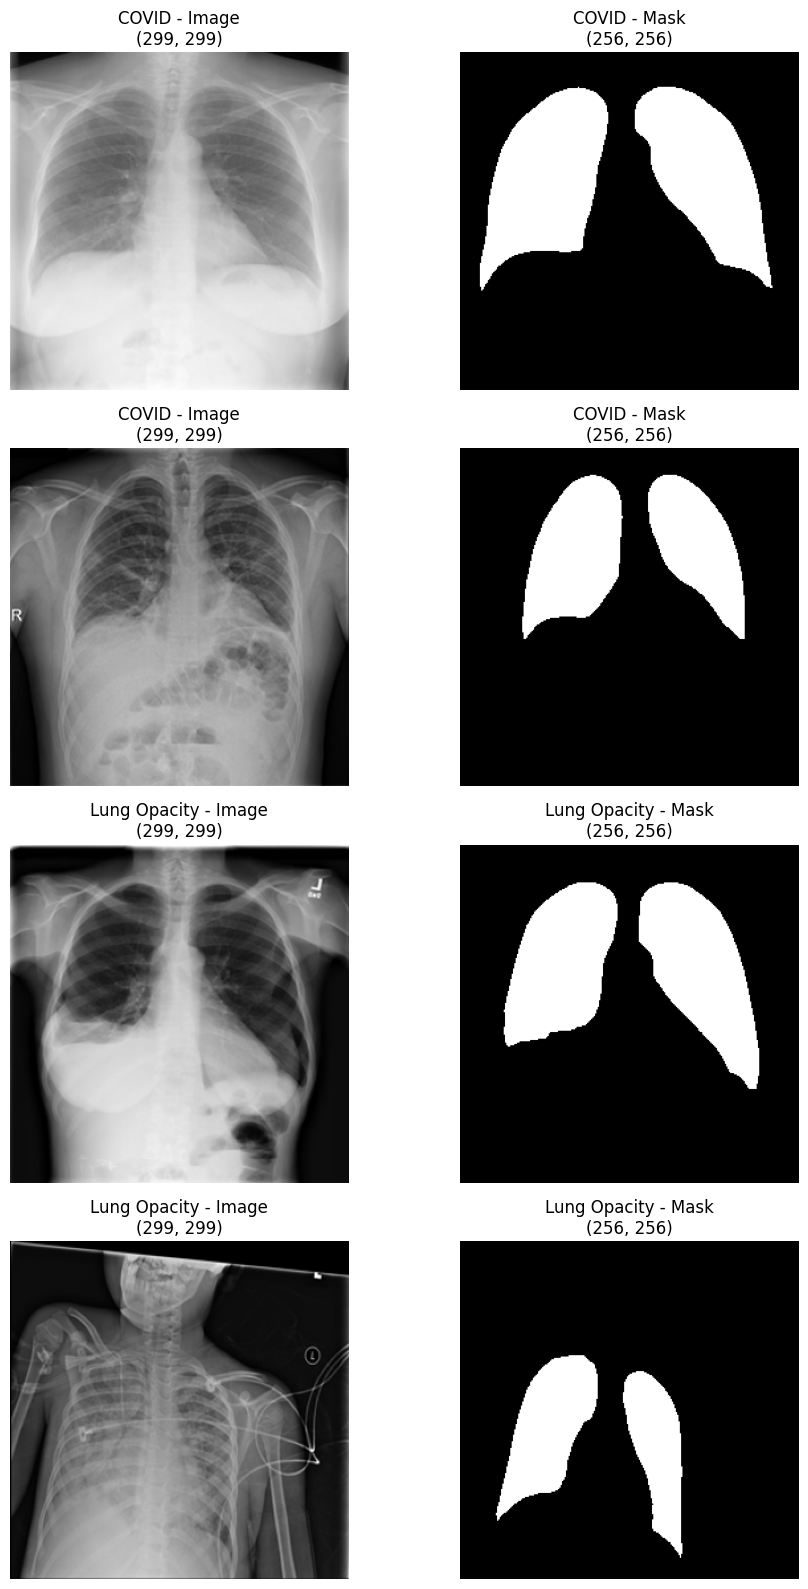

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

sample_indices = [0, 1345, 2690, 4035]

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for row, idx in enumerate(sample_indices):
    image = Image.open(df.iloc[idx]["image_path"]).convert("L")
    mask = Image.open(df.iloc[idx]["mask_path"]).convert("L")

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(
        f'{df.iloc[idx]["class_name"]} - Image\n{image.size}'
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(
        f'{df.iloc[idx]["class_name"]} - Mask\n{mask.size}'
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
from PIL import Image

coverage_results = []

for idx in sample_indices:
    image = np.array(Image.open(df.iloc[idx]["image_path"]).convert("L"))
    mask = np.array(Image.open(df.iloc[idx]["mask_path"]).convert("L"))

    mask_binary = mask > 0
    coverage = mask_binary.mean() * 100

    coverage_results.append({
        "class": df.iloc[idx]["class_name"],
        "image_shape": image.shape,
        "mask_shape": mask.shape,
        "mask_min": mask.min(),
        "mask_max": mask.max(),
        "mask_mean": mask.mean(),
        "lung_coverage_percent": coverage
    })

coverage_df = pd.DataFrame(coverage_results)

print(coverage_df.to_string(index=False))

print("\nOverall mask statistics:")
print("Minimum mask value:", coverage_df["mask_min"].min())
print("Maximum mask value:", coverage_df["mask_max"].max())
print("Minimum lung coverage:", coverage_df["lung_coverage_percent"].min())
print("Maximum lung coverage:", coverage_df["lung_coverage_percent"].max())

       class image_shape mask_shape  mask_min  mask_max  mask_mean  lung_coverage_percent
       COVID  (299, 299) (256, 256)         0       255  67.539825              26.486206
       COVID  (299, 299) (256, 256)         0       255  43.882599              17.208862
Lung Opacity  (299, 299) (256, 256)         0       255  58.773422              23.048401
Lung Opacity  (299, 299) (256, 256)         0       255  34.481964              13.522339

Overall mask statistics:
Minimum mask value: 0
Maximum mask value: 255
Minimum lung coverage: 13.5223388671875
Maximum lung coverage: 26.4862060546875


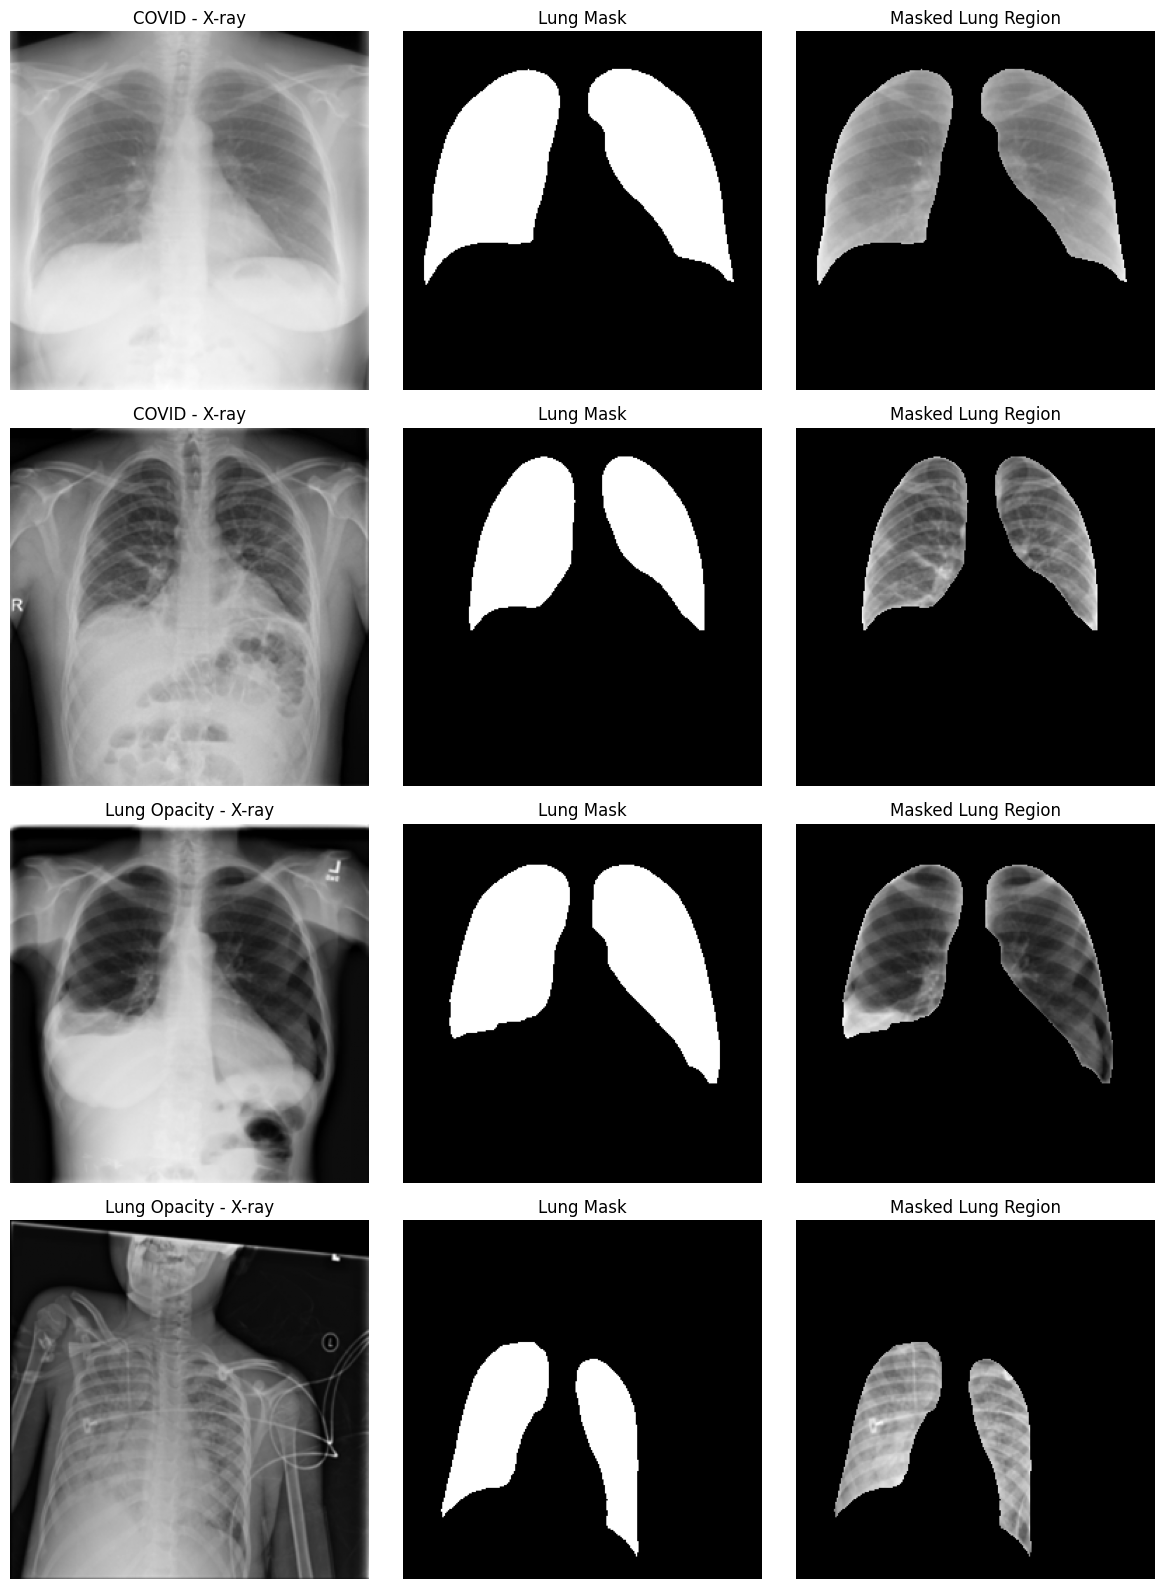

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_indices = [0, 1345, 2690, 4035]

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for row, idx in enumerate(sample_indices):
    image = Image.open(df.iloc[idx]["image_path"]).convert("L")
    mask = Image.open(df.iloc[idx]["mask_path"]).convert("L")

    image_resized = image.resize((256, 256), Image.Resampling.BILINEAR)
    mask_array = np.array(mask)
    image_array = np.array(image_resized)

    masked_image = image_array.copy()
    masked_image[mask_array == 0] = 0

    axes[row, 0].imshow(image_array, cmap="gray")
    axes[row, 0].set_title(f'{df.iloc[idx]["class_name"]} - X-ray')
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_array, cmap="gray")
    axes[row, 1].set_title("Lung Mask")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(masked_image, cmap="gray")
    axes[row, 2].set_title("Masked Lung Region")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

full_df = df.copy()

development_df, test_df = train_test_split(
    full_df,
    test_size=0.15,
    stratify=full_df["label"],
    random_state=42
)

heldout_test_paths = set(test_df["image_path"])

df = development_df.reset_index(drop=True)   # k-fold CV uses ONLY this

assert heldout_test_paths.isdisjoint(set(df["image_path"])), "Leak: test images found in the CV data!"

print(f"Full dataset            : {len(full_df)}")
print(f"Development set (k-fold): {len(df)}")
print(f"Held-out test set       : {len(test_df)}  (never used for k-fold, U-Net-for-CV, or model selection)")

Full dataset            : 5380
Development set (k-fold): 4573
Held-out test set       : 807  (never used for k-fold, U-Net-for-CV, or model selection)


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

IMG_SIZE = 224


In [10]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

unet = UNet().to(device)

sample_input = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    sample_output = unet(sample_input)

print("Device:", device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Parameters:", sum(p.numel() for p in unet.parameters()))

Device: cuda
Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 1, 224, 224])
Parameters: 7763041


In [11]:
class SegmentationDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

        self.image_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.Grayscale(num_output_channels=3),
            transforms.ToTensor()
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("L")
        mask = Image.open(row["mask_path"]).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        mask = (mask > 0.5).float()

        return image, mask


def dice_coefficient(pred, target, smooth=1.0):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    return dice.mean()


def dice_loss(pred, target, smooth=1.0):
    pred = torch.sigmoid(pred)

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(pred, target):
    return 0.5 * bce_loss(pred, target) + 0.5 * dice_loss(pred, target)


In [ ]:
import random

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)


In [12]:
from sklearn.model_selection import train_test_split

# identical call to the early split cell (same data, same seed) -> same test set; k-fold has not touched it
development_df, test_df = train_test_split(
    full_df,
    test_size=0.15,
    stratify=full_df["label"],
    random_state=42
)

development_df = development_df.copy()
test_df = test_df.copy()

assert set(test_df["image_path"]) == heldout_test_paths, "Test set differs from the one held out before k-fold!"

print(f"Development set: {len(development_df)}")
print(f"Independent test set: {len(test_df)}")

print("\nDevelopment distribution:")
print(development_df["class_name"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class_name"].value_counts().sort_index())

overlap = set(development_df["image_path"]).intersection(
    set(test_df["image_path"])
)

print(f"\nImage overlap: {len(overlap)}")

Development set: 4573
Independent test set: 807

Development distribution:
class_name
COVID              1143
Lung Opacity       1143
Normal             1144
Viral Pneumonia    1143
Name: count, dtype: int64

Test distribution:
class_name
COVID              202
Lung Opacity       202
Normal             201
Viral Pneumonia    202
Name: count, dtype: int64

Image overlap: 0


In [13]:
train_df, val_df = train_test_split(
    development_df,
    test_size=0.20,
    stratify=development_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train set: {len(train_df)}")
print(f"Validation set: {len(val_df)}")
print(f"Independent test set: {len(test_df)}")

print("\nTrain distribution:")
print(train_df["class_name"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class_name"].value_counts().sort_index())

Train set: 3658
Validation set: 915
Independent test set: 807

Train distribution:
class_name
COVID              915
Lung Opacity       914
Normal             915
Viral Pneumonia    914
Name: count, dtype: int64

Validation distribution:
class_name
COVID              228
Lung Opacity       229
Normal             229
Viral Pneumonia    229
Name: count, dtype: int64

Test distribution:
class_name
COVID              202
Lung Opacity       202
Normal             201
Viral Pneumonia    202
Name: count, dtype: int64


In [14]:
split_df = full_df.copy()

split_df["split"] = "development"

split_df.loc[split_df["image_path"].isin(train_df["image_path"]), "split"] = "train"
split_df.loc[split_df["image_path"].isin(val_df["image_path"]), "split"] = "validation"
split_df.loc[split_df["image_path"].isin(test_df["image_path"]), "split"] = "test"

split_path = "/kaggle/working/independent_test_split.csv"
split_df.to_csv(split_path, index=False)

print("Split saved successfully")
print(f"Path: {split_path}")
print(split_df["split"].value_counts())

Split saved successfully
Path: /kaggle/working/independent_test_split.csv
split
train         3658
validation     915
test           807
Name: count, dtype: int64


In [15]:
train_seg_dataset = SegmentationDataset(train_df)
val_seg_dataset = SegmentationDataset(val_df)
test_seg_dataset = SegmentationDataset(test_df)

print(f"Segmentation train samples: {len(train_seg_dataset)}")
print(f"Segmentation validation samples: {len(val_seg_dataset)}")
print(f"Segmentation test samples: {len(test_seg_dataset)}")

sample_image, sample_mask = train_seg_dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Mask shape: {sample_mask.shape}")
print(f"Image range: {sample_image.min().item():.4f} to {sample_image.max().item():.4f}")
print(f"Mask range: {sample_mask.min().item():.4f} to {sample_mask.max().item():.4f}")

Segmentation train samples: 3658
Segmentation validation samples: 915
Segmentation test samples: 807
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([1, 224, 224])
Image range: 0.0000 to 0.9098
Mask range: 0.0000 to 1.0000


In [16]:
set_seed(42)   # reproducible independent run (same helper as the CV pipeline)

unet_independent = UNet().to(device)

criterion_seg = nn.BCEWithLogitsLoss()

optimizer_seg = torch.optim.AdamW(
    unet_independent.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

print(f"U-Net parameters: {sum(p.numel() for p in unet_independent.parameters()):,}")
print(f"Device: {device}")

U-Net parameters: 7,763,041
Device: cuda


In [17]:
train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_seg_loader = DataLoader(
    val_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

num_seg_epochs = 15

best_seg_dice = 0.0
seg_history = {
    "train_loss": [],
    "train_dice": [],
    "val_loss": [],
    "val_dice": []
}

for epoch in range(num_seg_epochs):
    unet_independent.train()
    train_loss = 0.0
    train_dice = 0.0

    for images, masks in train_seg_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_seg.zero_grad()

        outputs = unet_independent(images)
        loss = segmentation_loss(outputs, masks)

        loss.backward()
        optimizer_seg.step()

        train_loss += loss.item()
        train_dice += dice_coefficient(outputs, masks).item()

    train_loss /= len(train_seg_loader)
    train_dice /= len(train_seg_loader)

    unet_independent.eval()
    val_loss = 0.0
    val_dice = 0.0

    with torch.no_grad():
        for images, masks in val_seg_loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = unet_independent(images)
            loss = segmentation_loss(outputs, masks)

            val_loss += loss.item()
            val_dice += dice_coefficient(outputs, masks).item()

    val_loss /= len(val_seg_loader)
    val_dice /= len(val_seg_loader)

    seg_history["train_loss"].append(train_loss)
    seg_history["train_dice"].append(train_dice)
    seg_history["val_loss"].append(val_loss)
    seg_history["val_dice"].append(val_dice)

    if val_dice > best_seg_dice:
        best_seg_dice = val_dice
        torch.save(
            unet_independent.state_dict(),
            "/kaggle/working/independent_best_unet.pth"
        )

    print(
        f"Epoch {epoch+1}/{num_seg_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

print(f"\nBest Validation Dice: {best_seg_dice:.4f}")
print("Best independent U-Net saved successfully")

Epoch 1/15 | Train Loss: 0.3561 | Train Dice: 0.8935 | Val Loss: 0.2872 | Val Dice: 0.9484
Epoch 2/15 | Train Loss: 0.2573 | Train Dice: 0.9544 | Val Loss: 0.2312 | Val Dice: 0.9607
Epoch 3/15 | Train Loss: 0.2064 | Train Dice: 0.9646 | Val Loss: 0.1924 | Val Dice: 0.9548
Epoch 4/15 | Train Loss: 0.1676 | Train Dice: 0.9683 | Val Loss: 0.1547 | Val Dice: 0.9662
Epoch 5/15 | Train Loss: 0.1352 | Train Dice: 0.9726 | Val Loss: 0.1224 | Val Dice: 0.9722
Epoch 6/15 | Train Loss: 0.1091 | Train Dice: 0.9762 | Val Loss: 0.1048 | Val Dice: 0.9734
Epoch 7/15 | Train Loss: 0.0889 | Train Dice: 0.9787 | Val Loss: 0.0845 | Val Dice: 0.9749
Epoch 8/15 | Train Loss: 0.0735 | Train Dice: 0.9804 | Val Loss: 0.0733 | Val Dice: 0.9762
Epoch 9/15 | Train Loss: 0.0624 | Train Dice: 0.9810 | Val Loss: 0.0639 | Val Dice: 0.9749
Epoch 10/15 | Train Loss: 0.0529 | Train Dice: 0.9826 | Val Loss: 0.0568 | Val Dice: 0.9760
Epoch 11/15 | Train Loss: 0.0454 | Train Dice: 0.9837 | Val Loss: 0.0496 | Val Dice: 0.97

In [18]:
unet_independent.load_state_dict(
    torch.load(
        "/kaggle/working/independent_best_unet.pth",
        map_location=device
    )
)

unet_independent.eval()

segmented_root = "/kaggle/working/independent_segmented"
os.makedirs(segmented_root, exist_ok=True)

def generate_segmented_images(dataframe, split_name):
    split_dir = os.path.join(segmented_root, split_name)
    os.makedirs(split_dir, exist_ok=True)

    loader = DataLoader(
        SegmentationDataset(dataframe),
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    paths = []

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device, non_blocking=True)

            outputs = unet_independent(images)
            masks = (torch.sigmoid(outputs) > 0.5).float()

            segmented = images * masks

            for image_tensor in segmented:
                image_tensor = image_tensor.mean(dim=0)
                image_tensor = image_tensor.clamp(0, 1)
                image_array = (image_tensor.cpu().numpy() * 255).astype(np.uint8)

                filename = f"{len(paths):05d}.png"
                save_path = os.path.join(split_dir, filename)

                Image.fromarray(image_array).save(save_path)
                paths.append(save_path)

    return paths

train_segmented_paths = generate_segmented_images(train_df, "train")
val_segmented_paths = generate_segmented_images(val_df, "validation")
test_segmented_paths = generate_segmented_images(test_df, "test")

train_df["independent_segmented_path"] = train_segmented_paths
val_df["independent_segmented_path"] = val_segmented_paths
test_df["independent_segmented_path"] = test_segmented_paths

print(f"Train segmented images: {len(train_segmented_paths)}")
print(f"Validation segmented images: {len(val_segmented_paths)}")
print(f"Test segmented images: {len(test_segmented_paths)}")
print(f"Segmented directory: {segmented_root}")

Train segmented images: 3658
Validation segmented images: 915
Test segmented images: 807
Segmented directory: /kaggle/working/independent_segmented


In [19]:
test_seg_loader = DataLoader(
    test_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

unet_independent.eval()
test_dice = 0.0
n_test = 0

with torch.no_grad():
    for images, masks in test_seg_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        outputs = unet_independent(images)
        d = dice_coefficient(outputs, masks).item()

        test_dice += d * images.size(0)   # weight by batch size -> exact mean over all test images
        n_test += images.size(0)

test_dice /= n_test

print(f"Test images      : {n_test}")
print(f"U-Net Validation Dice (best): {best_seg_dice:.4f} ({best_seg_dice*100:.2f}%)")
print(f"U-Net Test Dice             : {test_dice:.4f} ({test_dice*100:.2f}%)")

Test images      : 807
U-Net Validation Dice (best): 0.9799 (97.99%)
U-Net Test Dice             : 0.9804 (98.04%)


## Next steps

- Classification with ConvNeXt-Tiny + RepViT-M1 on the segmented images
- Grad-CAM explainability
- 5-fold cross-validation and independent test evaluation